📊 Well Test Analysis: Project Walkthrough
This project analyzes the provided drawdown test data to uncover key characteristics of your reservoir. We'll use Python to process the pressure data, identify the distinct flow patterns, and calculate the reservoir's permeability, skin factor, drainage area, and Dietz shape factor.

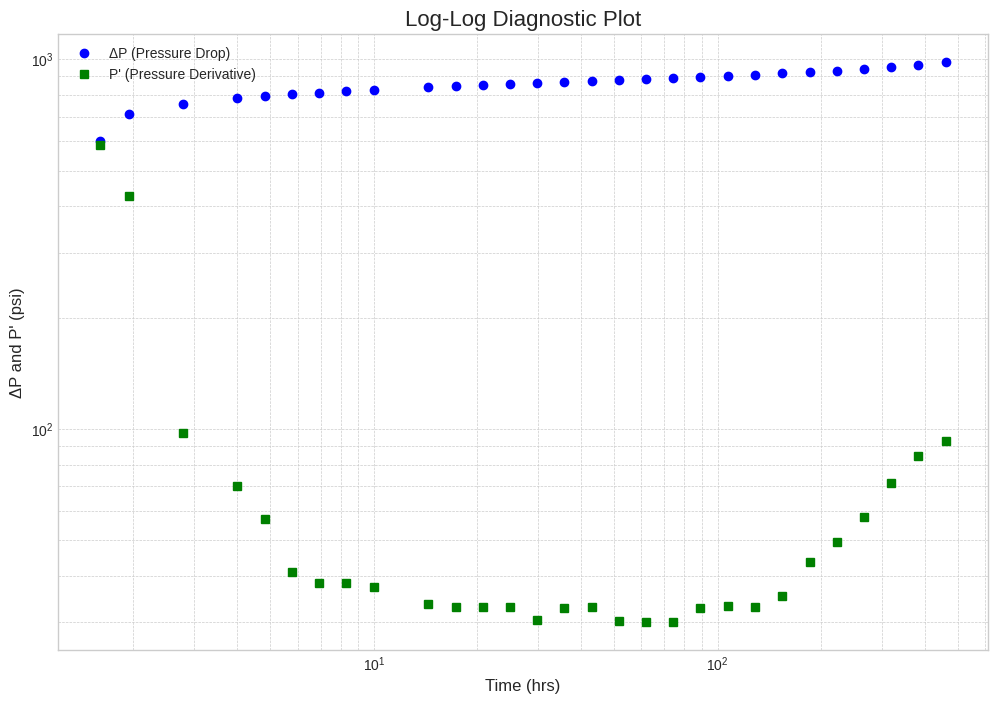

--- Well Test Analysis Results ---

--- Transient Zone (IARF) ---
Average derivative value (P'): 31.94 psi
Calculated Permeability (k): 7.28 mD

Semi-log plot slope (m): 72.70 psi/cycle
Calculated Skin (S): 5.85



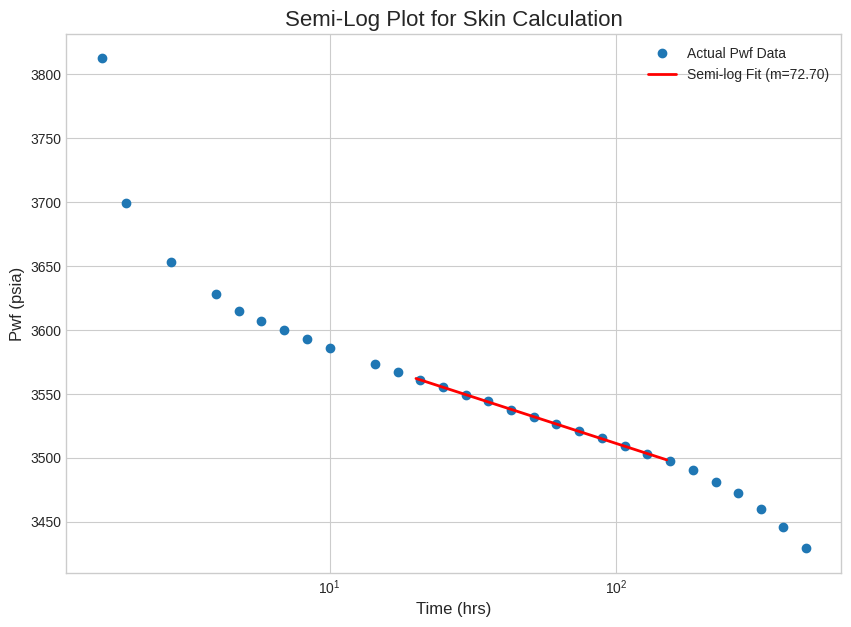

--- Semi-Steady State Zone ---
Unit slope constant C (from P'/t): 0.2160
Calculated Drainage Area (A): 6723051.80 sq. ft

Cartesian plot intercept: 3530.75 psi
Calculated Dietz Shape Factor (C_A): 17.41



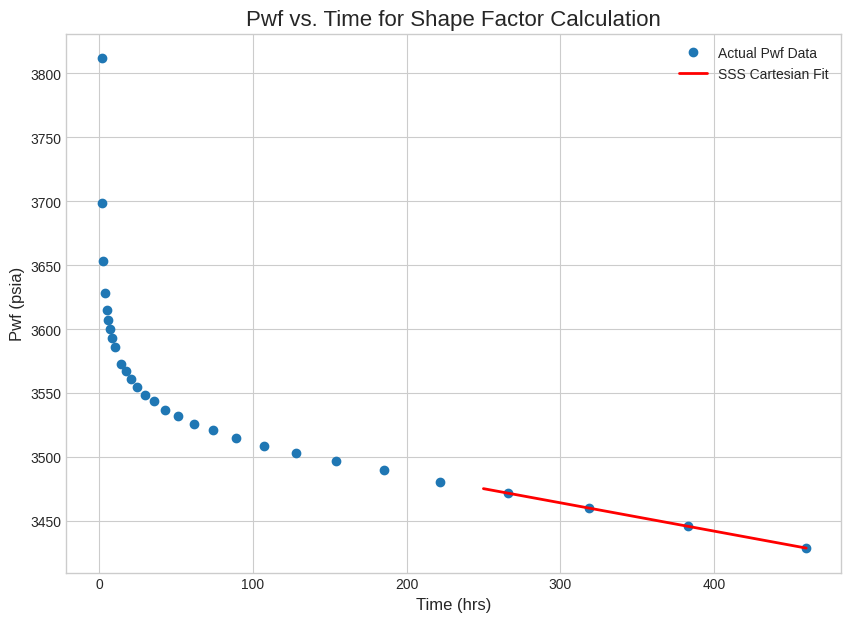

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --- 1. INPUT DATA ---

# Reservoir, Fluid, and Well Properties
params = {
    "Q": 250,        # Production rate, stb/d
    "h": 69,         # Formation thickness, ft
    "phi": 0.039,    # Porosity, fraction
    "ct": 17e-6,     # Total compressibility, psi^-1
    "Bo": 1.136,     # Oil formation volume factor, rb/stb
    "mu": 0.8,       # Oil viscosity, cp
    "rw": 0.198,     # Wellbore radius, ft
    "Pi": 4412,      # Initial reservoir pressure, psia
    "A_est": 151     # Estimated drainage area, acres
}

# Drawdown test data: Time (hrs) and Flowing Bottomhole Pressure (psia)
data = {
    't': [0, 1.6, 1.94, 2.79, 4.01, 4.82, 5.78, 6.94, 8.32, 9.99, 14.4, 17.3,
          20.7, 24.9, 29.8, 35.8, 43, 51.5, 61.8, 74.2, 89.1, 107, 128,
          154, 185, 222, 266, 319, 383, 460],
    'Pwf': [4412, 3812, 3699, 3653, 3628, 3615, 3607, 3600, 3593, 3586, 3573,
            3567, 3561, 3555, 3549, 3544, 3537, 3532, 3526, 3521, 3515,
            3509, 3503, 3497, 3490, 3481, 3472, 3460, 3446, 3429]
}
df = pd.DataFrame(data)


# --- 2. DATA PREPARATION ---

# Calculate pressure drop (delta P)
df['delta_P'] = params['Pi'] - df['Pwf']

# We can't use t=0 for log plots, so we'll work with a filtered dataframe
df_analysis = df[df['t'] > 0].copy()

# Calculate the pressure derivative d(delta_P) / d(ln(t))
# This is P' in your plots. We use numpy.gradient for a robust calculation.
df_analysis['P_prime'] = np.gradient(df_analysis['delta_P'], np.log(df_analysis['t']))


# --- 3. DIAGNOSTIC PLOT ---

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))
ax.loglog(df_analysis['t'], df_analysis['delta_P'], 'o', color='blue', label='ΔP (Pressure Drop)')
ax.loglog(df_analysis['t'], df_analysis['P_prime'], 's', color='green', label="P' (Pressure Derivative)")
ax.set_title('Log-Log Diagnostic Plot', fontsize=16)
ax.set_xlabel('Time (hrs)', fontsize=12)
ax.set_ylabel('ΔP and P\' (psi)', fontsize=12)
ax.legend()
ax.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()


# --- 4. ANALYSIS & CALCULATIONS ---

print("--- Well Test Analysis Results ---\n")

# --- 4a. TRANSIENT ZONE (IARF) ANALYSIS ---

# **USER INPUT**: Select the time range for the flat derivative (transient/IARF)
# From the plot, the derivative is flat roughly between t=20 and t=150 hrs
t_start_iarf = 20
t_end_iarf = 150
df_iarf = df_analysis[(df_analysis['t'] >= t_start_iarf) & (df_analysis['t'] <= t_end_iarf)]

# i. PERMEABILITY (k) from the derivative plot
# The flat line on the derivative plot gives us P'_avg
P_prime_avg = df_iarf['P_prime'].mean()
k = (70.6 * params['Q'] * params['Bo'] * params['mu']) / (params['h'] * P_prime_avg)
print(f"--- Transient Zone (IARF) ---")
print(f"Average derivative value (P'): {P_prime_avg:.2f} psi")
print(f"Calculated Permeability (k): {k:.2f} mD\n")

# ii. SKIN (S) from the semi-log plot (Pwf vs log10(t))
# Fit a straight line to the Pwf vs log10(t) data in the IARF region
slope_semilog, intercept_semilog, _, _, _ = linregress(np.log10(df_iarf['t']), df_iarf['Pwf'])

# Calculate Pwf at t=1hr (where log10(t)=0) from the fitted line
P_1hr = intercept_semilog
delta_P_1hr = params['Pi'] - P_1hr

# The slope of the line is m = abs(slope_semilog)
m = abs(slope_semilog)

# Calculate skin factor
term1 = delta_P_1hr / m
term2 = np.log10(k / (params['phi'] * params['mu'] * params['ct'] * params['rw']**2))
S = 1.1513 * (term1 - term2 + 3.23)
print(f"Semi-log plot slope (m): {m:.2f} psi/cycle")
print(f"Calculated Skin (S): {S:.2f}\n")

# Plotting the semi-log plot for verification
fig, ax = plt.subplots(figsize=(10, 7))
ax.semilogx(df_analysis['t'], df_analysis['Pwf'], 'o', label='Actual Pwf Data')
t_fit = np.logspace(np.log10(t_start_iarf), np.log10(t_end_iarf), 100)
pwf_fit = slope_semilog * np.log10(t_fit) + intercept_semilog
ax.semilogx(t_fit, pwf_fit, '-', color='red', linewidth=2, label=f'Semi-log Fit (m={m:.2f})')
ax.set_title('Semi-Log Plot for Skin Calculation', fontsize=16)
ax.set_xlabel('Time (hrs)', fontsize=12)
ax.set_ylabel('Pwf (psia)', fontsize=12)
ax.legend()
plt.show()

# --- 4b. SEMI-STEADY STATE (SSS) ANALYSIS ---

# **USER INPUT**: Select the time for the start of Semi-Steady State
# This is where the derivative has a unit slope, roughly after t=250 hrs
t_start_sss = 250
df_sss = df_analysis[df_analysis['t'] >= t_start_sss]

# i. DRAINAGE AREA (A) from the unit-slope line on the derivative plot
# Equation: log(P') = log(t) + log(C) => log(C) = log(P') - log(t)
# We calculate C = P'/t for each point and average it.
C = (df_sss['P_prime'] / df_sss['t']).mean()

# Now solve for Area (A)
A_acres = (0.2339 * params['Q'] * params['Bo']) / (C * params['h'] * params['phi'] * params['ct'])
A_sqft = A_acres * 43560  # Convert to sq. ft. for next calculation

print(f"--- Semi-Steady State Zone ---")
print(f"Unit slope constant C (from P'/t): {C:.4f}")
print(f"Calculated Drainage Area (A): {A_acres:.2f} sq. ft\n")

# ii. DIETZ SHAPE FACTOR (C_A) from Pwf vs t plot
# Fit a straight line to the Pwf vs t data in the SSS region
slope_cart, intercept_cart, _, _, _ = linregress(df_sss['t'], df_sss['Pwf'])

# Calculate Dietz Shape Factor (C_A) from the intercept of the Pwf vs t plot
gamma = np.exp(0.5772) # Euler's constant, approx 1.781
term1 = (params['Pi'] - intercept_cart) * (k * params['h']) / (141.2 * params['Q'] * params['Bo'] * params['mu'])
term2 = (4 * A_sqft) / (gamma * params['rw']**2)
C_A = term2 / np.exp(2 * term1)
print(f"Cartesian plot intercept: {intercept_cart:.2f} psi")
print(f"Calculated Dietz Shape Factor (C_A): {C_A:.2f}\n")

# Plotting the cartesian plot for verification
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(df_analysis['t'], df_analysis['Pwf'], 'o', label='Actual Pwf Data')
t_fit_sss = np.array([t_start_sss, df_analysis['t'].max()])
pwf_fit_sss = slope_cart * t_fit_sss + intercept_cart
ax.plot(t_fit_sss, pwf_fit_sss, '-', color='red', linewidth=2, label='SSS Cartesian Fit')
ax.set_title('Pwf vs. Time for Shape Factor Calculation', fontsize=16)
ax.set_xlabel('Time (hrs)', fontsize=12)
ax.set_ylabel('Pwf (psia)', fontsize=12)
ax.legend()
plt.show()